# Build 2: hotel overbooking — beginner walkthrough

This notebook walks through the uploaded CSV and calls the reproducible Python script. **The capacities are hypothetical; results are a retrospective scenario, not real-world recommendations.**

## Step 1 — Read the file
`pd.read_csv` reads each row as a reservation outcome. `head` previews a few records.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
df = pd.read_csv("../hotels.csv")
print(df.shape)
display(df.head())

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## Step 2 — Understand data quality
`isna().sum()` counts missing values; `duplicated()` counts *exact matches*, NOT confirmed duplicate bookings.

In [2]:
display(df.isna().sum().sort_values(ascending=False).head(12))
print("Matching rows:", df.duplicated().sum())
print(df.groupby("hotel")["is_canceled"].agg(["size", "mean"]))

company                      112593
agent                         16340
country                         488
children                          4
arrival_date_month                0
arrival_date_week_number          0
hotel                             0
is_canceled                       0
stays_in_weekend_nights           0
arrival_date_day_of_month         0
adults                            0
stays_in_week_nights              0
dtype: int64

Matching rows: 31994
               size      mean
hotel                        
City Hotel    79330  0.417270
Resort Hotel  40060  0.277634


## Step 3 — Create arrival date
Combine year, English month name and day to a datetime. This enables chronological splitting.

In [3]:
df["arrival_date"] = pd.to_datetime(df["arrival_date_year"].astype(str)+"-"+df["arrival_date_month"]+"-"+df["arrival_date_day_of_month"].astype(str),format="%Y-%B-%d")
df["shows"] = 1 - df["is_canceled"]
print(df["arrival_date"].min(), df["arrival_date"].max())

2015-07-01 00:00:00 2017-08-31 00:00:00


## Step 4 — Split by time
The 2017 test is kept unseen during selection.

In [4]:
train = df[df.arrival_date < "2016-07-01"]
validation = df[(df.arrival_date >= "2016-07-01") & (df.arrival_date < "2017-01-01")]
test = df[df.arrival_date >= "2017-01-01"]
print(len(train),len(validation),len(test))

49157 29546 40687


## Visual EDA — seven training-only charts

We examine only the **training period (through June 2016)** when exploring patterns. This avoids using the 2017 holdout to guide feature engineering. The following charts are descriptive associations, not causal effects. Every figure is saved in `figures/`. 

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from pathlib import Path
fig_dir = Path("figures")
fig_dir.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

def save_chart(filename):
    plt.tight_layout()
    plt.savefig(fig_dir / filename, dpi=170, bbox_inches="tight")
    plt.show()

print("EDA sample: TRAIN ONLY", train.shape)


EDA sample: TRAIN ONLY (49157, 34)


### 1. Cancellation rate by hotel

**Why this chart?** Compare cancellation risk across the two properties using training reservations only.

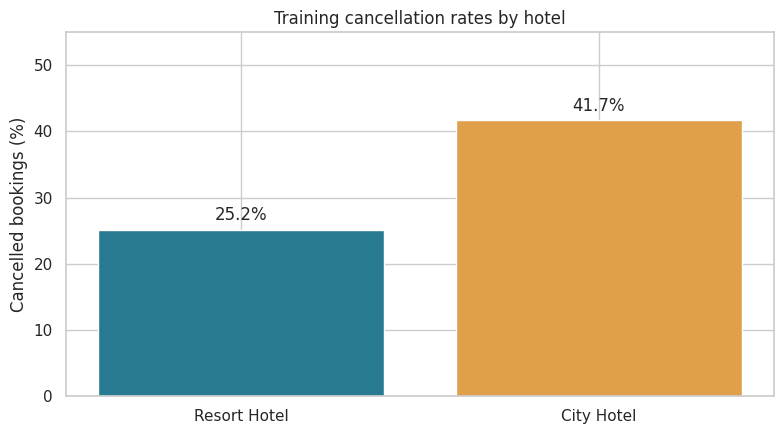

In [6]:
rates = train.groupby("hotel")["is_canceled"].mean().mul(100).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(rates.index, rates.values, color=["#287a91", "#e0a04b"])
ax.set(title="Training cancellation rates by hotel", ylabel="Cancelled bookings (%)", xlabel="")
ax.set_ylim(0, 55)
ax.bar_label(bars, fmt="%.1f%%", padding=4)
save_chart("01_cancellation_by_hotel.png")

**How to interpret:** Different hotel-level cancellation rates motivate hotel-specific forecasts. This is not evidence that cancellations alone determine a safe overbooking quantity.

### 2. Cancellation rate by lead time

**Why this chart?** Check whether time between reservation and arrival relates to cancellation probability.

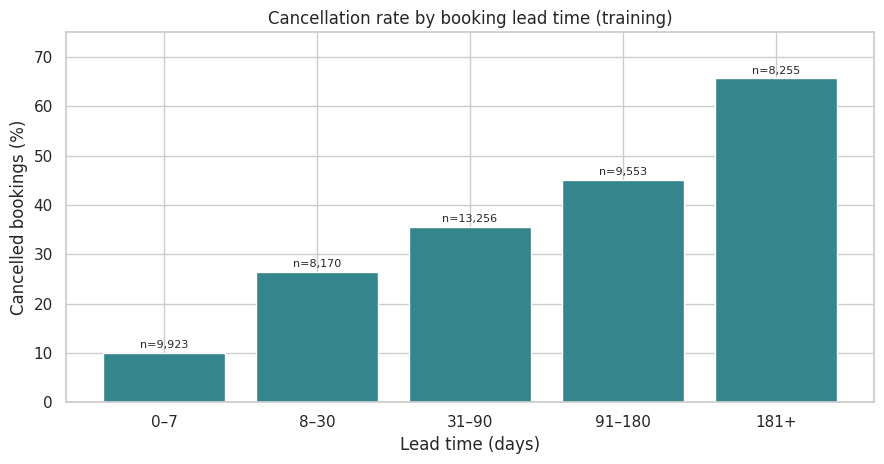

In [7]:
bins = [-1, 7, 30, 90, 180, float("inf")]
labels = ["0–7", "8–30", "31–90", "91–180", "181+"]
lead = train.copy()
lead["lead_bucket"] = pd.cut(lead["lead_time"], bins=bins, labels=labels)
lead_summary = lead.groupby("lead_bucket", observed=True)["is_canceled"].agg(["size", "mean"])
fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar(lead_summary.index.astype(str), lead_summary["mean"]*100, color="#34858c")
ax.set(title="Cancellation rate by booking lead time (training)", xlabel="Lead time (days)", ylabel="Cancelled bookings (%)", ylim=(0, 75))
for bar, n in zip(bars, lead_summary["size"]):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1, f"n={n:,}", ha="center", fontsize=8)
save_chart("02_lead_time.png")

**How to interpret:** Longer lead-time groups can have different observed cancellation risk. The group counts protect against overinterpreting tiny categories.

### 3. Monthly cancellation trends

**Why this chart?** Explore seasonality and differences between the city and resort. Train has July 2015–June 2016, so every calendar month appears once.

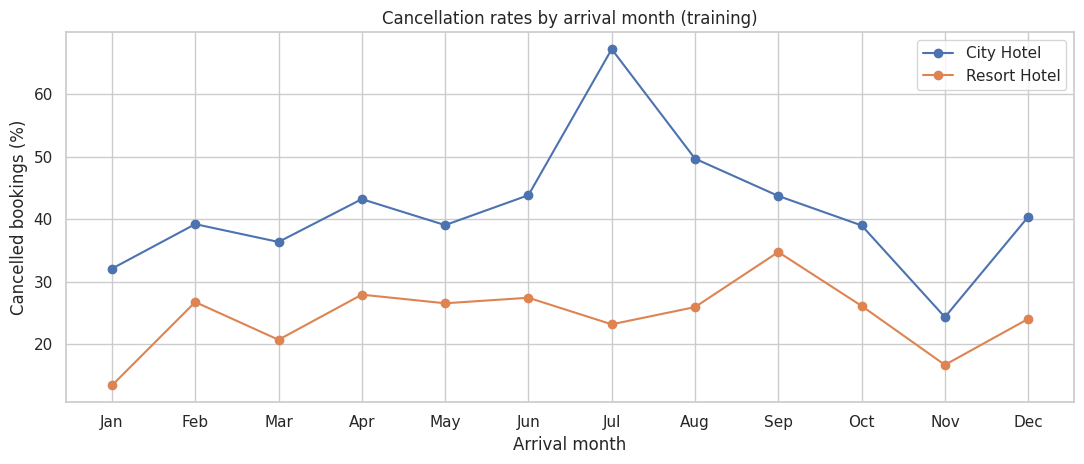

In [8]:
month_order = ["January","February","March","April","May","June","July","August","September","October","November","December"]
month_cancel = (train.groupby(["arrival_date_month", "hotel"], observed=True)["is_canceled"]
                .mean().mul(100).unstack("hotel").reindex(month_order))
fig, ax = plt.subplots(figsize=(11,4.8))
for hotel in month_cancel.columns:
    ax.plot(range(1,13), month_cancel[hotel], marker="o", label=hotel)
ax.set(title="Cancellation rates by arrival month (training)", xlabel="Arrival month", ylabel="Cancelled bookings (%)", xticks=range(1,13))
ax.set_xticklabels([m[:3] for m in month_order])
ax.legend()
save_chart("03_monthly_cancellations.png")

**How to interpret:** Seasonal variation suggests that a global annual cancellation rate may not capture all booking behavior. Each point is based on only one occurrence of that month in training.

### 4. ADR distribution and outliers

**Why this chart?** Inspect room-rate skew and irregular nonpositive values before using ADR in loss calculations.

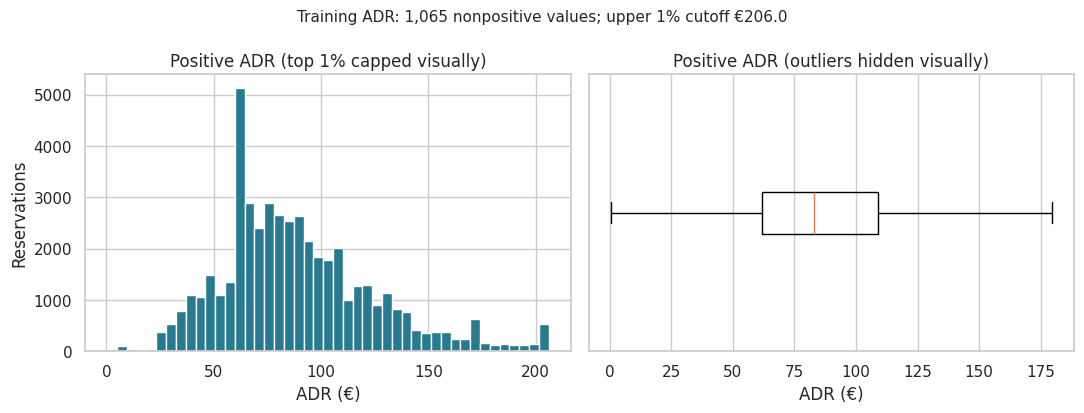

In [9]:
positive_adr = train.loc[train["adr"]>0, "adr"]
limit = positive_adr.quantile(0.99)
fig, axes = plt.subplots(1,2,figsize=(11,4.2))
axes[0].hist(positive_adr.clip(upper=limit), bins=45, color="#287a91", edgecolor="white")
axes[0].set(title="Positive ADR (top 1% capped visually)", xlabel="ADR (€)", ylabel="Reservations")
axes[1].boxplot(positive_adr, vert=False, showfliers=False)
axes[1].set(title="Positive ADR (outliers hidden visually)", xlabel="ADR (€)", yticks=[])
fig.suptitle(f"Training ADR: {(train['adr']<=0).sum():,} nonpositive values; upper 1% cutoff €{limit:,.1f}", fontsize=11)
save_chart("04_adr_distribution.png")

**How to interpret:** ADR is right-skewed. Capping and hiding outliers is only for visualization; these plot changes do not modify the original dataset. The pipeline explicitly handles nonpositive ADR when constructing costs.

### 5. Deposit type and cancellations

**Why this chart?** Examine an operationally meaningful categorical feature.

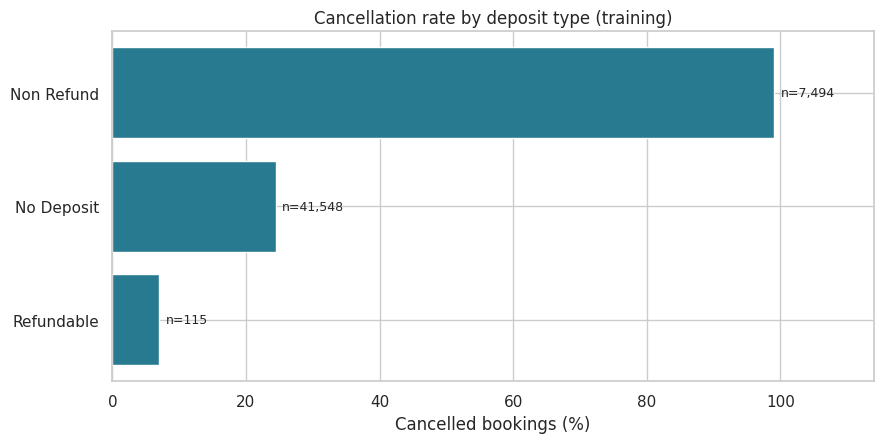

In [10]:
dep = train.groupby("deposit_type")["is_canceled"].agg(["size","mean"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(9,4.6))
bars = ax.barh(dep.index, dep["mean"]*100, color="#287a91")
ax.set(title="Cancellation rate by deposit type (training)", xlabel="Cancelled bookings (%)", ylabel="")
for bar, n in zip(bars, dep["size"]):
    ax.text(bar.get_width()+1,bar.get_y()+bar.get_height()/2,f"n={n:,}",va="center",fontsize=9)
ax.set_xlim(0, max(105,dep["mean"].max()*100+15))
save_chart("05_deposit_type.png")

**How to interpret:** Deposit categories can have very different observed outcomes, but these correlations are not necessarily causal and may depend on hotel policies.

### 6. Market segment and cancellations

**Why this chart?** Compare channels or segments that may have different cancellation behavior.

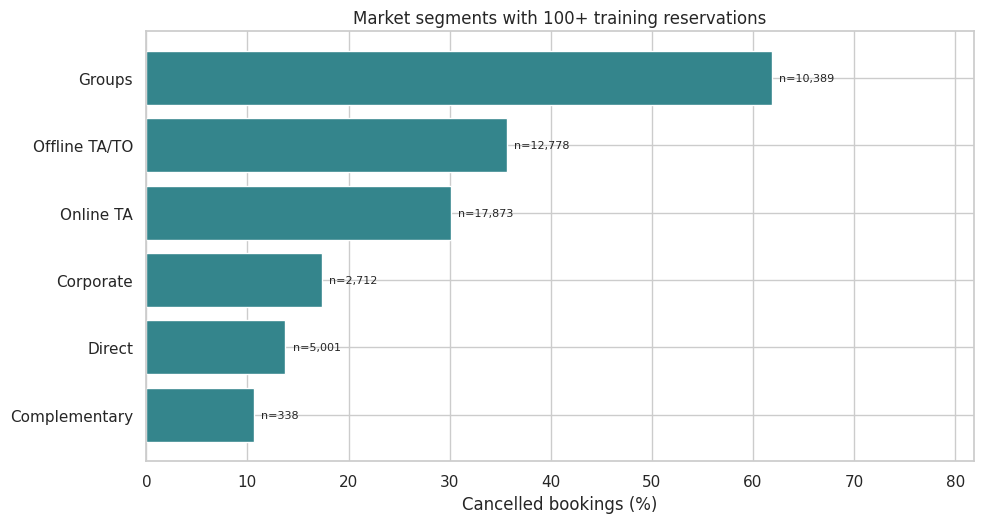

In [11]:
seg = train.groupby("market_segment")["is_canceled"].agg(["size","mean"])
seg = seg[seg["size"]>=100].sort_values("mean")
fig, ax = plt.subplots(figsize=(10,5.4))
bars=ax.barh(seg.index,seg["mean"]*100,color="#34858c")
ax.set(title="Market segments with 100+ training reservations", xlabel="Cancelled bookings (%)", ylabel="")
for b,n in zip(bars,seg["size"]): ax.text(b.get_width()+0.7,b.get_y()+b.get_height()/2,f"n={n:,}",va="center",fontsize=8)
ax.set_xlim(0, max(70,seg["mean"].max()*100+20))
save_chart("06_market_segment.png")

**How to interpret:** Segment-level patterns may be informative for individualized probability modeling. Segments with fewer than 100 training rows are omitted from this chart only.

### 7. Numerical correlation heatmap

**Why this chart?** Spot redundant numerical variables and coarse linear relationships with the target.

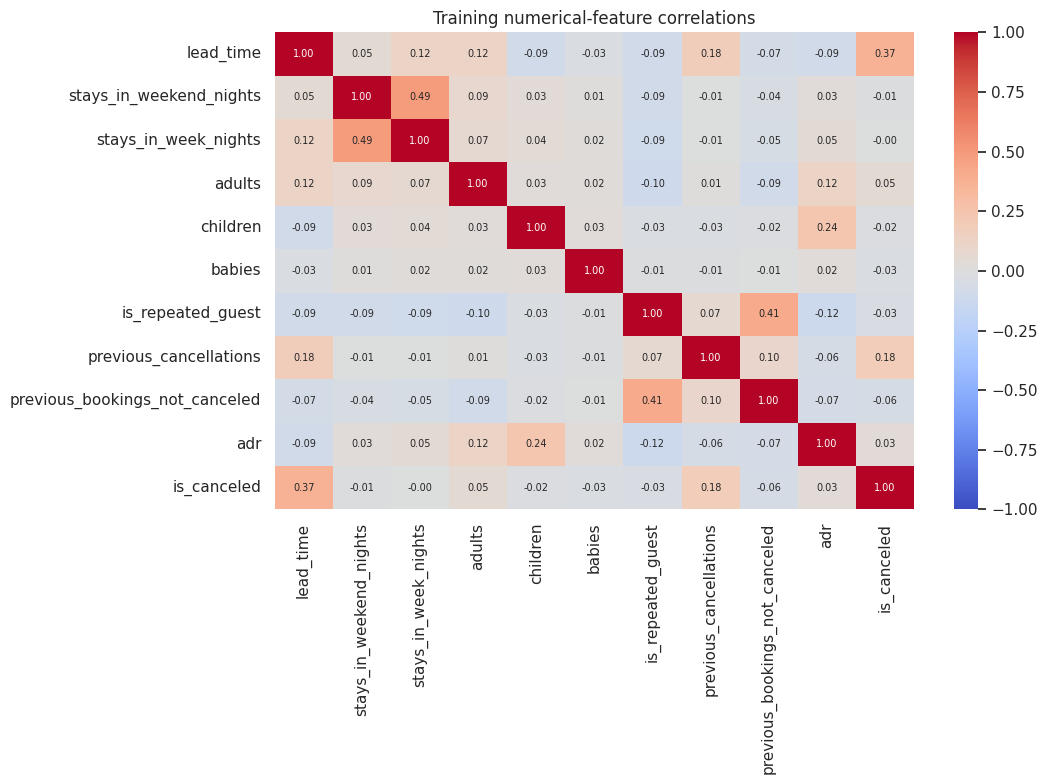

In [12]:
from build2_analysis import NUM
numeric_cols = NUM + ["is_canceled"]
corr = train[numeric_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11,8))
sns.heatmap(corr, vmin=-1, vmax=1, center=0, cmap="coolwarm", annot=True, fmt=".2f", annot_kws={"size":7}, ax=ax)
ax.set_title("Training numerical-feature correlations")
save_chart("07_correlation_heatmap.png")

**How to interpret:** Correlation is only a pairwise linear statistic. Small correlation does not mean a feature is useless to a classification model, and the heatmap does not establish causality.

## Step 5 — Understand the money
For each eligible night, `capacity` is an **assumed** scenario value, `shows` is observed arrival count, and `k` is extra guaranteed-show guests in this simplified simulator. This is not realistic multiday occupancy.

In [13]:
capacity, shows, k, night_value = 20, 18, 4, 100
empty = max(0,capacity-shows-k)
walked = max(0,shows+k-capacity)
loss = empty*night_value + walked*300
print({"empty":empty,"walked":walked,"loss_eur":loss})

{'empty': 0, 'walked': 2, 'loss_eur': 600}


## Step 6 — Train safely
See `build2_analysis.py`: only booking-plausible inputs enter a preprocessing pipeline and a LogisticRegression model. Final status and status date are explicitly excluded.

In [14]:
from build2_analysis import NUM, CAT, LEAKY
print("Numeric features", NUM)
print("Categorical features", CAT)
print("Excluded potentially leaky features", LEAKY)

Numeric features ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'adr']
Categorical features ['hotel', 'arrival_date_month', 'market_segment', 'distribution_channel', 'deposit_type', 'customer_type', 'reserved_room_type', 'meal']
Excluded potentially leaky features ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes', 'days_in_waiting_list']


## Step 7 — Run the full experiment
The command below freezes each rule using H2 2016 and writes the 2017 score table once. It may take a few seconds depending on machine and installed packages.

In [15]:
import subprocess, sys
subprocess.run([sys.executable,"build2_analysis.py","--csv","../hotels.csv","--out","results","--city-capacity","150","--resort-capacity","100"],check=True)

DATA: 119390 Train: 49157 Val: 29546 Test: 40687
MODEL: {'validation_auc': 0.7318, 'validation_brier': 0.1831, 'test_auc': 0.7721, 'test_brier': 0.177}
FROZEN POLICIES:
        hotel          method  parameter  validation_feasible  validation_cost_eur  validation_walks_per_1000
  City Hotel            flat         20                 True           1575890.02                      0.000
  City Hotel historical_rate          0                 True           1582911.73                      0.000
  City Hotel        logistic          0                 True           1582698.02                      0.000
  City Hotel            zero          0                 True           1637805.12                      0.000
Resort Hotel            flat          7                 True           1245151.09                      0.000
Resort Hotel historical_rate         20                 True           1247455.09                      0.000
Resort Hotel        logistic         20                 True       

CompletedProcess(args=['/opt/pyvenv/bin/python', 'build2_analysis.py', '--csv', '../hotels.csv', '--out', 'results', '--city-capacity', '150', '--resort-capacity', '100'], returncode=0)

## Step 8 — Compare frozen policies

In [16]:
results = pd.read_csv("results/test_comparison.csv")
display(results[["hotel","method","parameter_frozen","cost_eur","walks_per_1000","savings_vs_zero_eur","test_under_ceiling"]])

,hotel,method,parameter_frozen,cost_eur,walks_per_1000,savings_vs_zero_eur,test_under_ceiling
0,City Hotel,flat,20,2151287.74,0.000,87996.10,True
1,City Hotel,historical_rate,0,2162128.94,0.000,77154.90,True
2,City Hotel,logistic,0,2154683.54,0.000,84600.30,True
3,City Hotel,zero,0,2239283.84,0.000,0.00,True
4,Resort Hotel,flat,7,1586733.54,4.691,-6383.17,True
5,Resort Hotel,historical_rate,20,1580590.07,2.082,-239.70,True
6,Resort Hotel,logistic,20,1579506.17,1.970,844.20,True
7,Resort Hotel,zero,0,1580350.37,1.973,0.00,True


## Prediction model diagnostics — two charts

Fit the **same preprocessing and Logistic Regression specification** as in `build2_analysis.py`. The 2017 probabilities here are used strictly for the frozen-model diagnostic charts, not for changing model selection.

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve
from build2_analysis import NUM, CAT

model = Pipeline([
    ("prep", ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", StandardScaler())]), NUM),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CAT)
    ])),
    ("classifier", LogisticRegression(max_iter=400, solver="liblinear", random_state=42))
])
model.fit(train[NUM + CAT], train["shows"])
val_prob = model.predict_proba(validation[NUM + CAT])[:, 1]
test_prob = model.predict_proba(test[NUM + CAT])[:, 1]
print(f"Validation AUC: {roc_auc_score(validation['shows'], val_prob):.4f}")
print(f"Test AUC (diagnostic only): {roc_auc_score(test['shows'], test_prob):.4f}")
print(f"Validation Brier: {brier_score_loss(validation['shows'], val_prob):.4f}")
print(f"Test Brier (diagnostic only): {brier_score_loss(test['shows'], test_prob):.4f}")

Validation AUC: 0.7318
Test AUC (diagnostic only): 0.7721
Validation Brier: 0.1831
Test Brier (diagnostic only): 0.1770


### 8. ROC curve

**Why this chart?** Check whether the model ranks likely non-canceled bookings above canceled ones; validation is used for selection, and test is diagnostic only.

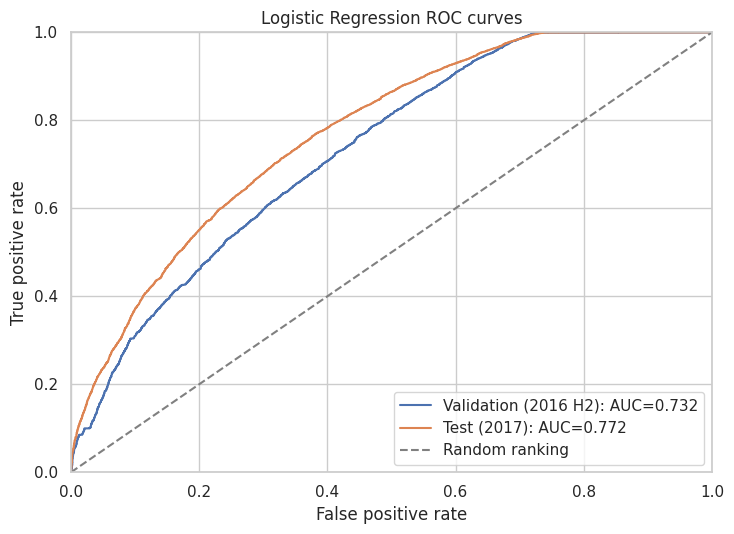

In [18]:
fig, ax = plt.subplots(figsize=(7.5,5.5))
for frame, prob, label in [(validation,val_prob,"Validation (2016 H2)"),(test,test_prob,"Test (2017)")]:
    fpr,tpr,_ = roc_curve(frame["shows"],prob)
    auc=roc_auc_score(frame["shows"],prob)
    ax.plot(fpr,tpr,label=f"{label}: AUC={auc:.3f}")
ax.plot([0,1],[0,1],"--",color="gray",label="Random ranking")
ax.set(title="Logistic Regression ROC curves",xlabel="False positive rate",ylabel="True positive rate",xlim=(0,1),ylim=(0,1))
ax.legend(loc="lower right")
save_chart("08_roc_curve.png")

**How to interpret:** AUC measures ranking discrimination; it does not directly measure euro savings, nor does it establish that show probabilities are well calibrated.

### 9. Probability calibration

**Why this chart?** Check whether predicted probability groups approximately match observed non-cancellation rates.

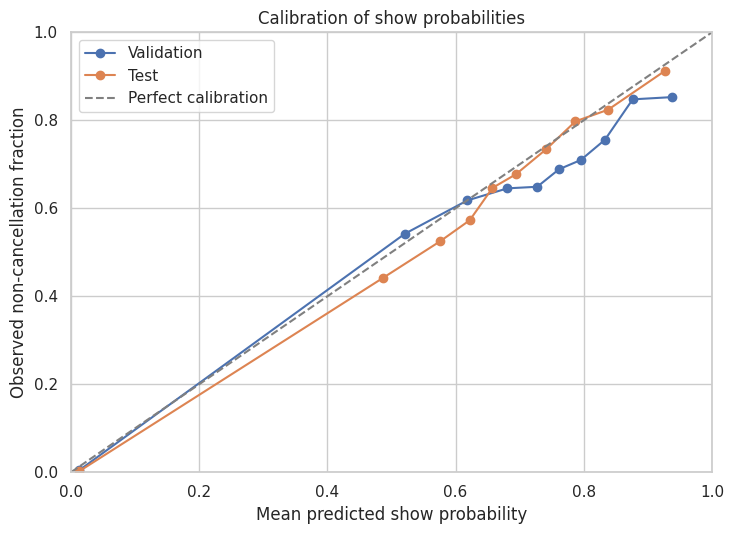

In [19]:
fig, ax = plt.subplots(figsize=(7.5,5.5))
for frame, prob, label in [(validation,val_prob,"Validation"),(test,test_prob,"Test")]:
    actual, predicted = calibration_curve(frame["shows"], prob, n_bins=10, strategy="quantile")
    ax.plot(predicted,actual,marker="o",label=label)
ax.plot([0,1],[0,1],"--",color="gray",label="Perfect calibration")
ax.set(title="Calibration of show probabilities",xlabel="Mean predicted show probability",ylabel="Observed non-cancellation fraction",xlim=(0,1),ylim=(0,1))
ax.legend()
save_chart("09_calibration.png")

**How to interpret:** Points closer to the diagonal are better calibrated. Calibration is especially relevant because the decision rule sums probabilities to estimate arrivals.

## Business optimization — three charts

These use the **frozen 2016 policies** and **2017 scenario results** written by the Python script. Assumed capacities (150 City / 100 Resort) and the guaranteed-show extra-reservation simplification are NOT facts about the hotels. The 2017 results must not be used to retune parameters.

### 10. Total simulated euro cost by strategy

**Why this chart?** Compare the actual business objective across each hotel and policy.

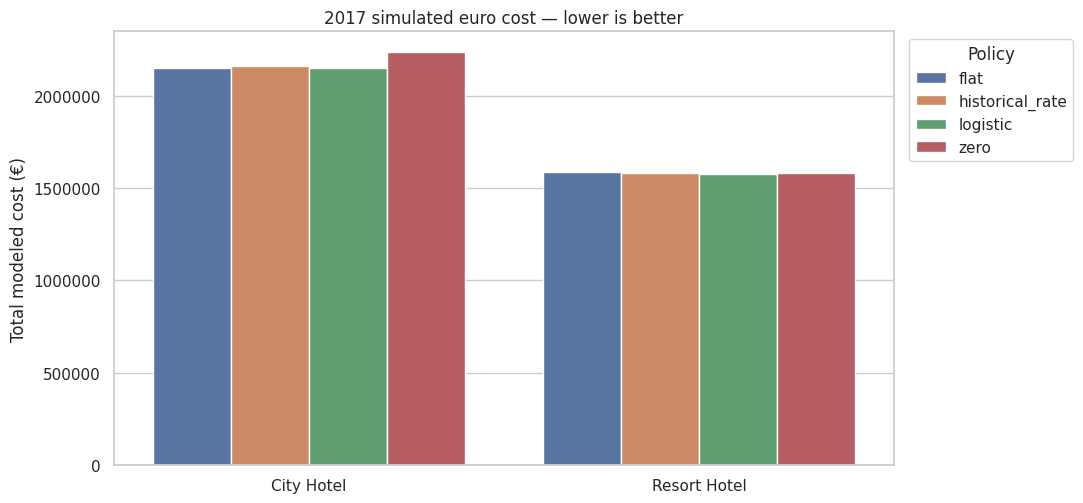

In [20]:
res = pd.read_csv("results/test_comparison.csv")
fig, ax=plt.subplots(figsize=(11,5.2))
sns.barplot(data=res, x="hotel", y="cost_eur", hue="method", errorbar=None, ax=ax)
ax.set(title="2017 simulated euro cost — lower is better",xlabel="",ylabel="Total modeled cost (€)")
ax.ticklabel_format(style="plain",axis="y")
ax.legend(title="Policy",bbox_to_anchor=(1.01,1),loc="upper left")
save_chart("10_cost_comparison.png")

**How to interpret:** Choose the lowest euro cost among policies that satisfy the walkaway ceiling. The bars are close in height because absolute costs are large; inspect the numeric comparison table for differences.

### 11. Walkaway ceiling check

**Why this chart?** Show that a low-cost rule must also satisfy the client safety limit.

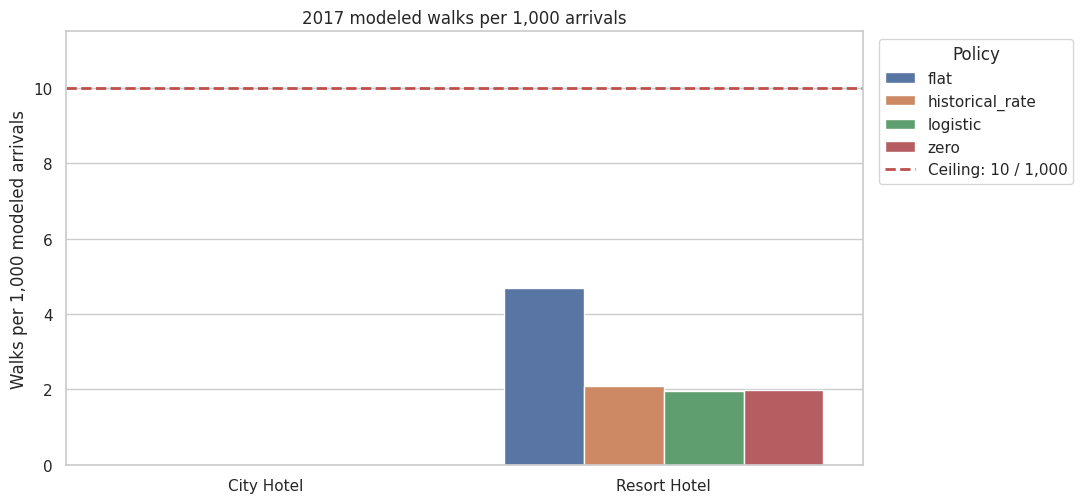

In [21]:
fig, ax=plt.subplots(figsize=(11,5.2))
sns.barplot(data=res, x="hotel", y="walks_per_1000", hue="method", errorbar=None, ax=ax)
ax.axhline(10, color="#bd514a",linestyle="--",linewidth=2,label="Ceiling: 10 / 1,000")
ax.set(title="2017 modeled walks per 1,000 arrivals",xlabel="",ylabel="Walks per 1,000 modeled arrivals",ylim=(0,11.5))
ax.legend(title="Policy",bbox_to_anchor=(1.01,1),loc="upper left")
save_chart("11_walkaway_ceiling.png")

**How to interpret:** A feasible rule must remain at or below 10 walks per 1,000 arrivals. The model uses a simplified arrival denominator; the contractual definition should be confirmed with the client.

### 12. Validation cost vs safety buffer

**Why this chart?** Make the 2016 selection process auditable. A lower buffer usually means more aggressive overbooking.

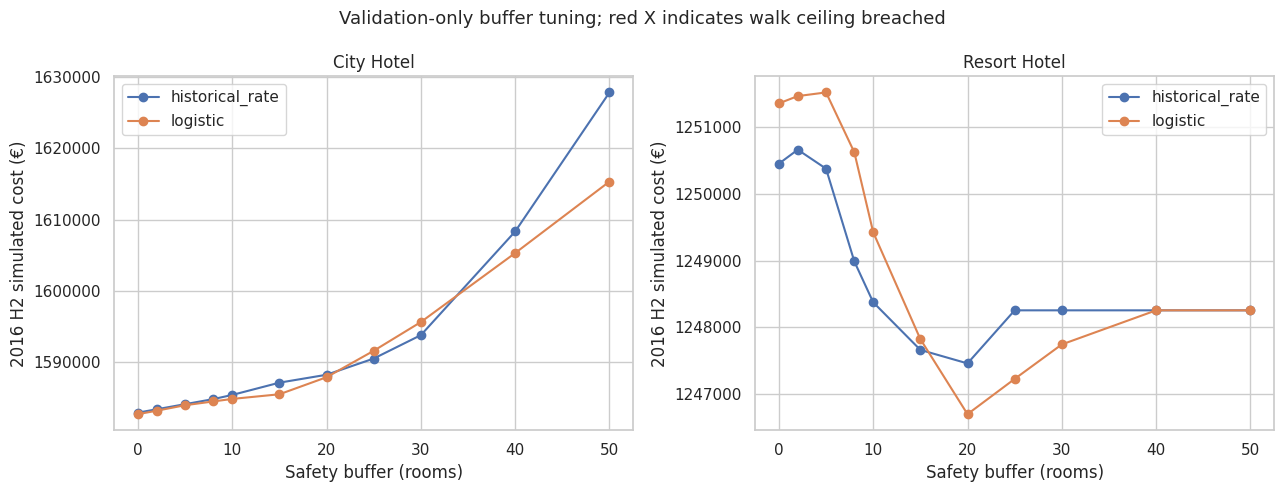

In [22]:
grid = pd.read_csv("results/validation_grid.csv")
fig, axes = plt.subplots(1,2,figsize=(13,5),sharey=False)
for ax,hotel in zip(axes,["City Hotel","Resort Hotel"]):
    part=grid[(grid["hotel"]==hotel)&(grid["method"].isin(["historical_rate","logistic"]))]
    for method, grp in part.groupby("method"):
        ax.plot(grp["parameter"],grp["cost_eur"],marker="o",label=method)
        infeasible=grp[~grp["eligible"]]
        if len(infeasible): ax.scatter(infeasible["parameter"],infeasible["cost_eur"],color="#bd514a",marker="x",s=80,zorder=5)
    ax.set(title=hotel,xlabel="Safety buffer (rooms)",ylabel="2016 H2 simulated cost (€)")
    ax.ticklabel_format(style="plain",axis="y")
    ax.legend()
fig.suptitle("Validation-only buffer tuning; red X indicates walk ceiling breached",fontsize=13)
save_chart("12_validation_buffer_tradeoff.png")

**How to interpret:** The frozen buffer is selected from validation-period euro cost subject to feasibility. This is not a 2017 optimization curve; never tune on the test set.

## Step 9 — Explain the caveat to your panel
We do **not** have real capacities, booking-state cutoffs, cancellation timestamps, or a unique booking ID. We also use arrival-night cohorts rather than all nights of stay. All euro numbers are scenario outcomes only. Do not optimize the final rule on 2017 after seeing test metrics.

## Step 10 — Try a sensitivity run
Change only assumed capacities below; compare outcomes as distinct **scenarios**, not a test-set optimization. For rigorous estimates, obtain the hotel's actual daily capacity and snapshots.

In [23]:
# Example scenario (run only when you want to examine assumption sensitivity):
# subprocess.run([sys.executable,"build2_analysis.py","--csv","../hotels.csv",
#                 "--out","results_capacity_scenario","--city-capacity","170",
#                 "--resort-capacity","110"],check=True)

## Overall takeaways

- **EDA:** Hotel, lead time, seasonality, deposit type and market segment show useful descriptive patterns; verify any feature is actually known at decision time.
- **Model:** Logistic Regression forecasts non-cancellation probability. ROC-AUC checks ranking, calibration checks probability reliability.
- **Decision:** A hotel-specific frozen policy is evaluated by euro cost **under** the walkaway ceiling, rather than by ROC-AUC alone.
- **Limitations:** Capacities are assumed, extra bookings are modeled as guaranteed arrivals, and multiday occupancy / operational booking snapshots are unavailable. These charts are illustrative—not a deployable overbooking policy.

Use the 12 exported PNG files in the presentation where relevant; quote all euro numbers as **scenario results**.